<font size=10>**TARGET & FEATURE REPRESENTATIONS**</font> <a class="anchor" id='title'></a>

**Master's in Data Science & Advanced Analytics - NOVA IMS (26/27)**

**Course**: *Data Stream Mining — Practical Assignment I (PA48)*

**Project**: *Weather Windows for Outdoor Races — Angra do Heroísmo vs Braga*

**Group PA48**
- Beatriz Marques 20231605
- Duarte Fernandes 20231619

**Question**: *Which city offers more reliable weather windows for recurring outdoor races?*

**Pipeline step**: This notebook reproduces **step 2** and the target/feature/mask part of **step 3** of `python src/practical_assignment.py --config config.yaml`: freeze the pooled warm-up threshold, build T6, construct representations A and B, and use the same eligibility mask for both representations.

| Notebook | What it does |
|---|---|
| 01 — `01_data_collection_and_quality.ipynb` | Data collection and quality |
| **02 — `02_target_and_features.ipynb`** | **Target, features and shared mask** |
| 03 — `03_prequential_evaluation.ipynb` | Evaluation and audit outputs |
| 04 — `04_results_and_figures.ipynb` | Results, figures and audit checks |

<font color='#BFD72F' size=6>**TABLE OF CONTENTS**</font> <a class="anchor" id='toc'></a>

- [1. Imports](#1)

- [2. Data](#2)

- [3. Target T6 — Adverse Outdoor Event](#3)
    - [3.1 Frozen Threshold from the Pooled Warm-up](#3_1)
    - [3.2 Building $y_t$](#3_2)
    - [3.3 Class Balance](#3_3)
        - [Insights](#insights_1)

- [4. Feature Representations](#4)
    - [4.1 Representation A — Previous State](#4_1)
    - [4.2 Representation B — Stream-aware Context](#4_2)
    - [4.3 Leakage Checks](#4_3)
    - [4.4 Shared Evaluation Mask](#4_4)
        - [Insights](#insights_2)

# <font color='#BFD72F' size=6>**1. Imports**</font> <a class="anchor" id="1"></a>

[Back to TOC](#toc)

In [11]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Get the absolute path of the source code folder
source_code_path = os.path.abspath('../src')

# Add the source code folder to sys.path
if source_code_path not in sys.path:
    sys.path.append(source_code_path)

from data_loader import ROOT, load_config, fetch_city
from targets import RAIN_MM, compute_thresholds, make_target
from features import BASE, representation_a, representation_b

# <font color='#BFD72F' size=6>**2. Data**</font> <a class="anchor" id="2"></a>

[Back to TOC](#toc)

In [13]:
cfg = load_config(ROOT / 'config.yaml')
period = cfg['period']
warm_n = cfg['warmup']['n_hours']
raw_dir = ROOT / cfg['paths']['raw_data']
data = {}
names = {}
for key in ('city_a', 'city_b'):
    c = cfg['cities'][key]
    names[key] = c['name']
    data[key] = fetch_city(
        c['name'], c['latitude'], c['longitude'],
        period['start_date'], period['end_date'], period['timezone'],
        raw_dir=raw_dir,
    )
target = cfg['assignment']['target']
assert target == 'T6', 'This notebook is designed for the configured T6 assignment.'
display(pd.DataFrame([{'city': names[k], 'rows': len(v)} for k, v in data.items()]))

,city,rows
0,Angra do Heroismo,50376
1,Braga,50376


# <font color='#BFD72F' size=6>**3. Target T6 — Adverse Outdoor Event**</font> <a class="anchor" id="3"></a>

[Back to TOC](#toc)

The **T6** label is built by `make_target` using the frozen wind threshold and `RAIN_MM = 0.1`:

$y_t = 1 \iff P_t \ge 0.1\ \text{mm} \lor W_t \ge \tau_W$

Here, $P_t$ is precipitation and $W_t$ is wind speed at time $t$. The current measurements define the **label**, not the current feature vector. `make_target` leaves the label missing where its source data are missing.

## <font color='#BFD72F' size=5>3.1 Frozen Threshold from the Pooled Warm-up</font> <a class="anchor" id="3_1"></a>

[Back to TOC](#toc)

In [14]:
thresholds = compute_thresholds(data['city_a'], data['city_b'], warm_n, target, cfg['targets'])
assert thresholds['T5'] == thresholds['T6_rule_1']
tau_W = thresholds['T5']
print(f'Frozen tau_W (pooled warm-up wind Q0.80): {tau_W} km/h')

Frozen tau_W (pooled warm-up wind Q0.80): 26.9 km/h


## <font color='#BFD72F' size=5>3.2 Building <i>y</i><sub>t</sub></font> <a class="anchor" id="3_2"></a>

[Back to TOC](#toc)

In [15]:
y = {key: make_target(df, target, thresholds, cfg['targets']) for key, df in data.items()}
display(pd.concat({names[key]: series for key, series in y.items()}, axis=1).head())

,Angra do Heroismo,Braga
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0


## <font color='#BFD72F' size=5>3.3 Class Balance</font> <a class="anchor" id="3_3"></a>

[Back to TOC](#toc)

,labelled_rows,event_rate_all,event_rate_warmup,event_rate_post_warmup,rain_only_share,wind_only_share,both_share
city,,,,,,,
Angra do Heroismo,50376,0.406285,0.620833,0.403174,0.797381,0.042703,0.159916
Braga,50376,0.224651,0.334722,0.223055,0.958558,0.003446,0.037996


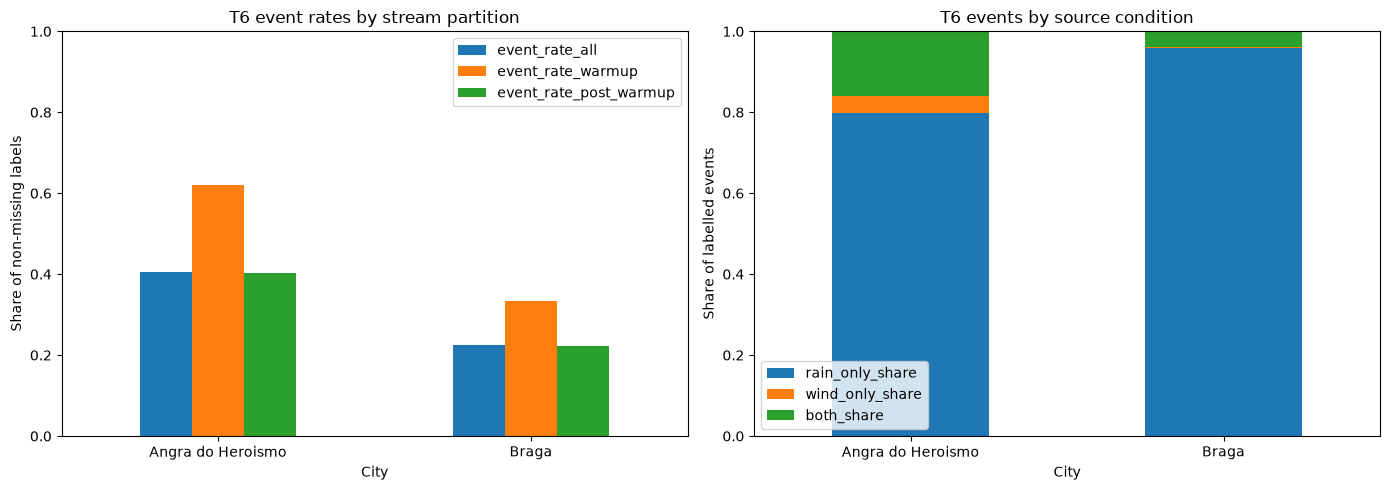

In [16]:
balance_rows = []
for key, df in data.items():
    labels_y = y[key]
    warm = pd.Series(df.index < warm_n, index=df.index)
    rain = df['precipitation'].ge(RAIN_MM)
    wind = df['wind_speed'].ge(tau_W)
    events = labels_y.eq(1) & labels_y.notna()
    n_events = int(events.sum())
    shares = {
        'rain_only_share': int((events & rain & ~wind).sum()),
        'wind_only_share': int((events & wind & ~rain).sum()),
        'both_share': int((events & rain & wind).sum()),
    }
    balance_rows.append({
        'city': names[key], 'labelled_rows': int(labels_y.notna().sum()),
        'event_rate_all': labels_y.mean(),
        'event_rate_warmup': labels_y[warm].mean(),
        'event_rate_post_warmup': labels_y[~warm].mean(),
        **{column: count / n_events if n_events else np.nan for column, count in shares.items()},
    })
balance_df = pd.DataFrame(balance_rows).set_index('city')
display(balance_df)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
balance_df[['event_rate_all', 'event_rate_warmup', 'event_rate_post_warmup']].plot.bar(ax=axes[0])
axes[0].set_title('T6 event rates by stream partition')
axes[0].set_ylabel('Share of non-missing labels')
axes[0].set_xlabel('City')
axes[0].set_ylim(0, 1)
balance_df[['rain_only_share', 'wind_only_share', 'both_share']].plot.bar(stacked=True, ax=axes[1])
axes[1].set_title('T6 events by source condition')
axes[1].set_ylabel('Share of labelled events')
axes[1].set_xlabel('City')
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
plt.show()

# <font color='#BFD72F' size=6>**4. Feature Representations**</font> <a class="anchor" id="4"></a>

[Back to TOC](#toc)

## <font color='#BFD72F' size=5>4.1 Representation A — Previous State</font> <a class="anchor" id="4_1"></a>

[Back to TOC](#toc)

In [17]:
reps = {key: {'A': representation_a(df)} for key, df in data.items()}
for key in data:
    print(f"{names[key]} | A: {reps[key]['A'].shape[1]} features")
    display(reps[key]['A'].head())

Angra do Heroismo | A: 4 features


,temperature_lag1,relative_humidity_lag1,precipitation_lag1,wind_speed_lag1
0,NaN,NaN,NaN,NaN
1,13.6,82.0,0.0,12.6
2,13.6,83.0,0.0,13.4
3,13.5,84.0,0.0,12.6
4,13.3,86.0,0.0,12.6


Braga | A: 4 features


,temperature_lag1,relative_humidity_lag1,precipitation_lag1,wind_speed_lag1
0,NaN,NaN,NaN,NaN
1,3.6,93.0,0.0,6.6
2,2.3,93.0,0.0,6.9
3,0.9,94.0,0.0,9.2
4,1.0,94.0,0.0,8.0


## <font color='#BFD72F' size=5>4.2 Representation B — Stream-aware Context</font> <a class="anchor" id="4_2"></a>

[Back to TOC](#toc)

In [18]:
windows = cfg['features']['windows']
for key, df in data.items():
    reps[key]['B'] = representation_b(df, windows, y=y[key])
feature_columns = reps['city_a']['B'].columns.tolist()
feature_groups = {
    'Previous state': [f'{c}_lag1' for c in BASE],
    'Lagged change': [f'{c}_delta1' for c in BASE],
    'Rolling mean': [f'{c}_mean{w}' for w in windows for c in BASE],
    'Rolling standard deviation': [f'{c}_std{w}' for w in windows for c in BASE],
    'Rain-hour count': [f'rain_hours_{w}' for w in windows],
    'Lagged event rate': [f'event_rate_{w}' for w in windows],
}
display(pd.DataFrame([
    {'type': group, 'columns': ', '.join(c for c in columns if c in feature_columns),
     'n_features': sum(c in feature_columns for c in columns)}
    for group, columns in feature_groups.items()
]))
for key in data:
    print(f"{names[key]} | B: {reps[key]['B'].shape[1]} features")
    display(reps[key]['B'].head())

,type,columns,n_features
0,Previous state,"temperature_lag1, relative_humidity_lag1, prec...",4
1,Lagged change,"temperature_delta1, relative_humidity_delta1, ...",4
2,Rolling mean,"temperature_mean6, relative_humidity_mean6, pr...",8
3,Rolling standard deviation,"temperature_std6, relative_humidity_std6, prec...",8
4,Rain-hour count,"rain_hours_6, rain_hours_24",2
5,Lagged event rate,"event_rate_6, event_rate_24",2


Angra do Heroismo | B: 28 features


,temperature_lag1,relative_humidity_lag1,precipitation_lag1,wind_speed_lag1,temperature_delta1,relative_humidity_delta1,precipitation_delta1,wind_speed_delta1,temperature_mean6,temperature_std6,...,temperature_mean24,temperature_std24,relative_humidity_mean24,relative_humidity_std24,precipitation_mean24,precipitation_std24,wind_speed_mean24,wind_speed_std24,rain_hours_24,event_rate_24
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,13.6,82.0,0.0,12.6,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,13.6,83.0,0.0,13.4,0.0,1.0,0.0,0.8,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,13.5,84.0,0.0,12.6,-0.1,1.0,0.0,-0.8,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,13.3,86.0,0.0,12.6,-0.2,2.0,0.0,0.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Braga | B: 28 features


,temperature_lag1,relative_humidity_lag1,precipitation_lag1,wind_speed_lag1,temperature_delta1,relative_humidity_delta1,precipitation_delta1,wind_speed_delta1,temperature_mean6,temperature_std6,...,temperature_mean24,temperature_std24,relative_humidity_mean24,relative_humidity_std24,precipitation_mean24,precipitation_std24,wind_speed_mean24,wind_speed_std24,rain_hours_24,event_rate_24
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3.6,93.0,0.0,6.6,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.3,93.0,0.0,6.9,-1.3,0.0,0.0,0.3,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.9,94.0,0.0,9.2,-1.4,1.0,0.0,2.3,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.0,94.0,0.0,8.0,0.1,0.0,0.0,-1.2,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## <font color='#BFD72F' size=5>4.3 Leakage Checks</font> <a class="anchor" id="4_3"></a>

[Back to TOC](#toc)

In [19]:
assert 6 in windows, 'The required event_rate_6 check needs a six-hour window.'
for key, df in data.items():
    for rep_name, X in reps[key].items():
        for c in BASE:
            pd.testing.assert_series_equal(
                X[f'{c}_lag1'], df[c].shift(1), check_names=False,
            )
        assert 'precipitation' not in X.columns
        assert 'wind_speed' not in X.columns
    np.testing.assert_allclose(
        reps[key]['B']['event_rate_6'].to_numpy(),
        y[key].shift(1).rolling(6).mean().to_numpy(),
        equal_nan=True,
    )
print('All leakage checks passed')

All leakage checks passed


## <font color='#BFD72F' size=5>4.4 Shared Evaluation Mask</font> <a class="anchor" id="4_4"></a>

[Back to TOC](#toc)

In [20]:
valid = {}
is_warm = {}
mask_rows = []
for key, df in data.items():
    valid[key] = reps[key]['B'].notna().all(axis=1) & y[key].notna()
    is_warm[key] = pd.Series(df.index < warm_n, index=df.index)
    mask_rows.append({
        'city': names[key], 'total_rows': len(df),
        'rows_dropped_by_mask': int((~valid[key]).sum()),
        'warmup_rows_inside_valid': int((valid[key] & is_warm[key]).sum()),
        'rows_evaluated': int((valid[key] & ~is_warm[key]).sum()),
    })
display(pd.DataFrame(mask_rows))

,city,total_rows,rows_dropped_by_mask,warmup_rows_inside_valid,rows_evaluated
0,Angra do Heroismo,50376,24,696,49656
1,Braga,50376,24,696,49656
